In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

import os

for root, dirs, files in os.walk("Dataset"):
    for file in files:
        if file.endswith("bank-full.csv"):
            print(os.path.join(root, file))


Dataset\bank-full.csv


In [3]:

# Load dataset
df = pd.read_csv("Dataset/bank-full.csv")

# Display first 5 rows
df.head()


,"age;""job"";""marital"";""education"";""default"";""balance"";""housing"";""loan"";""contact"";""day"";""month"";""duration"";""campaign"";""pdays"";""previous"";""poutcome"";""y"""
0,"58;""management"";""married"";""tertiary"";""no"";2143..."
1,"44;""technician"";""single"";""secondary"";""no"";29;""..."
2,"33;""entrepreneur"";""married"";""secondary"";""no"";2..."
3,"47;""blue-collar"";""married"";""unknown"";""no"";1506..."
4,"33;""unknown"";""single"";""unknown"";""no"";1;""no"";""n..."


In [4]:

# Load dataset with correct separator
df = pd.read_csv("Dataset/bank-full.csv", sep=";")

# Display first 5 rows
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 45211
Number of Columns: 17


In [6]:

print(df.columns.tolist())


['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [7]:

# Dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [8]:

# Check missing values
print(df.isnull().sum())


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [9]:

# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [10]:

# Check target variable distribution
print(df['y'].value_counts())
print("\nPercentage Distribution:")
print(df['y'].value_counts(normalize=True) * 100)


y
no     39922
yes     5289
Name: count, dtype: int64

Percentage Distribution:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


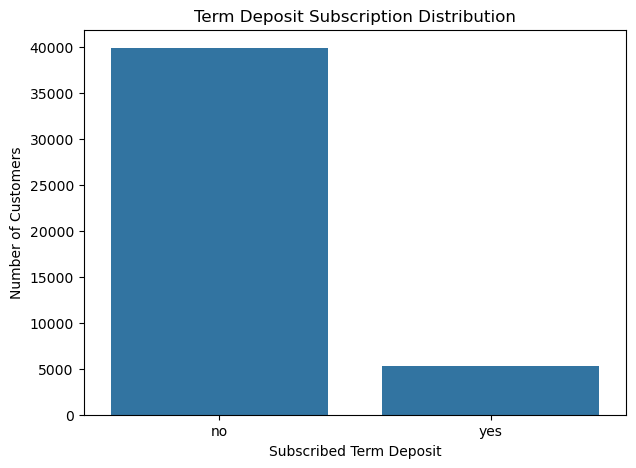

In [11]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Term Deposit Subscription Distribution')
plt.xlabel('Subscribed Term Deposit')
plt.ylabel('Number of Customers')

plt.show()


In [12]:

print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())


Missing Values:
0

Duplicate Records:
0


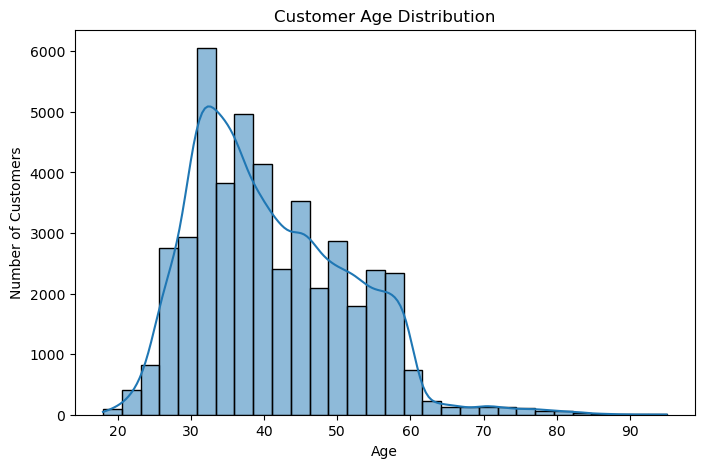

In [13]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()


**Age Distribution – Observation:**

The majority of bank customers belong to the 30–40 years age group. Customer participation decreases as age increases beyond 60 years. This indicates that middle-aged customers form a significant portion of the bank's customer base.

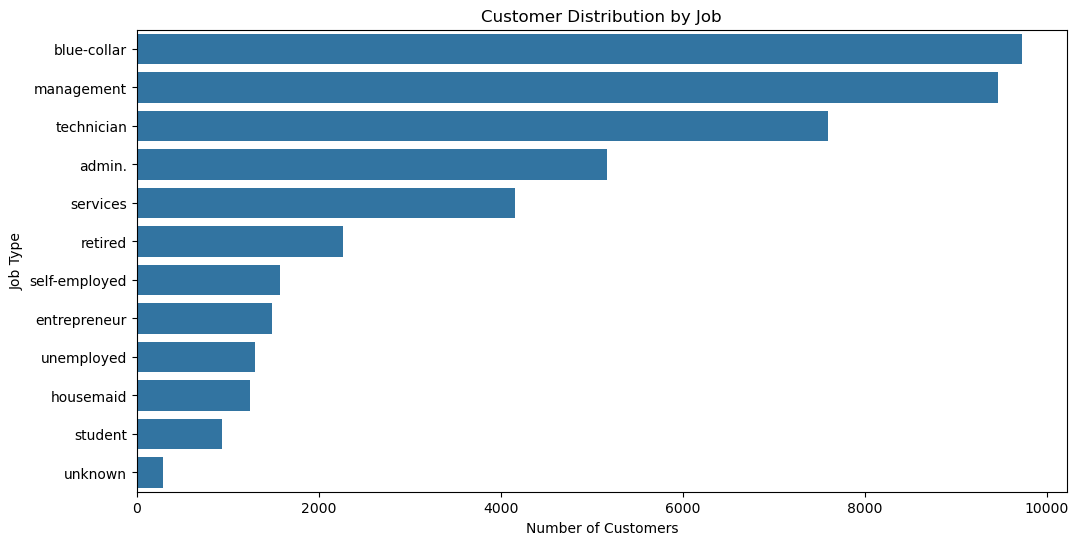

In [14]:

plt.figure(figsize=(12, 6))

sns.countplot(data=df, y='job', order=df['job'].value_counts().index)

plt.title('Customer Distribution by Job')
plt.xlabel('Number of Customers')
plt.ylabel('Job Type')

plt.show()


**Job Distribution – Observation:**

The majority of customers belong to the Blue-collar, Management, and Technician professions. These job categories represent a significant portion of the bank's customer base. The bank can analyze these professional groups further to identify potential term deposit subscribers and improve its marketing campaigns.

<Figure size 1200x600 with 0 Axes>

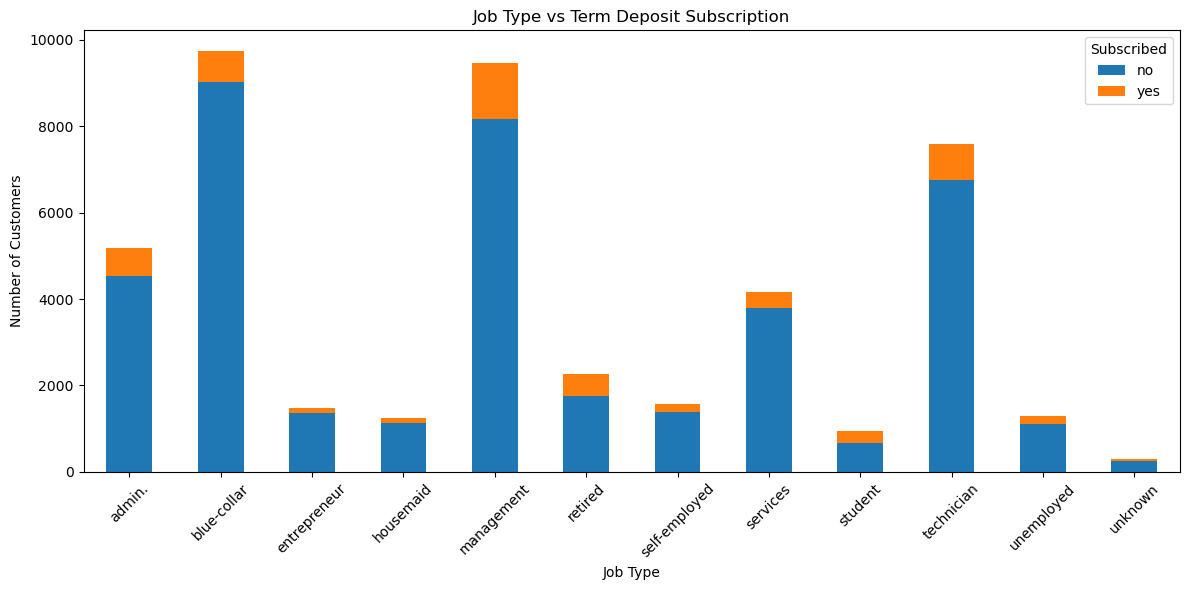

In [15]:

plt.figure(figsize=(12, 6))

job_subscription = pd.crosstab(df['job'], df['y'])

job_subscription.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Job Type vs Term Deposit Subscription')
plt.xlabel('Job Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.legend(title='Subscribed')

plt.tight_layout()
plt.show()


Job vs Term Deposit – Observation:

The Blue-collar and Management categories have the highest number of customers. However, customer count alone does not indicate subscription probability. The bank should analyze the subscription rate for each job category to identify the most promising customer segments.

y                 no    yes
job                        
student        71.32  28.68
retired        77.21  22.79
unemployed     84.50  15.50
management     86.24  13.76
admin.         87.80  12.20
self-employed  88.16  11.84
unknown        88.19  11.81
technician     88.94  11.06
services       91.12   8.88
housemaid      91.21   8.79
entrepreneur   91.73   8.27
blue-collar    92.73   7.27


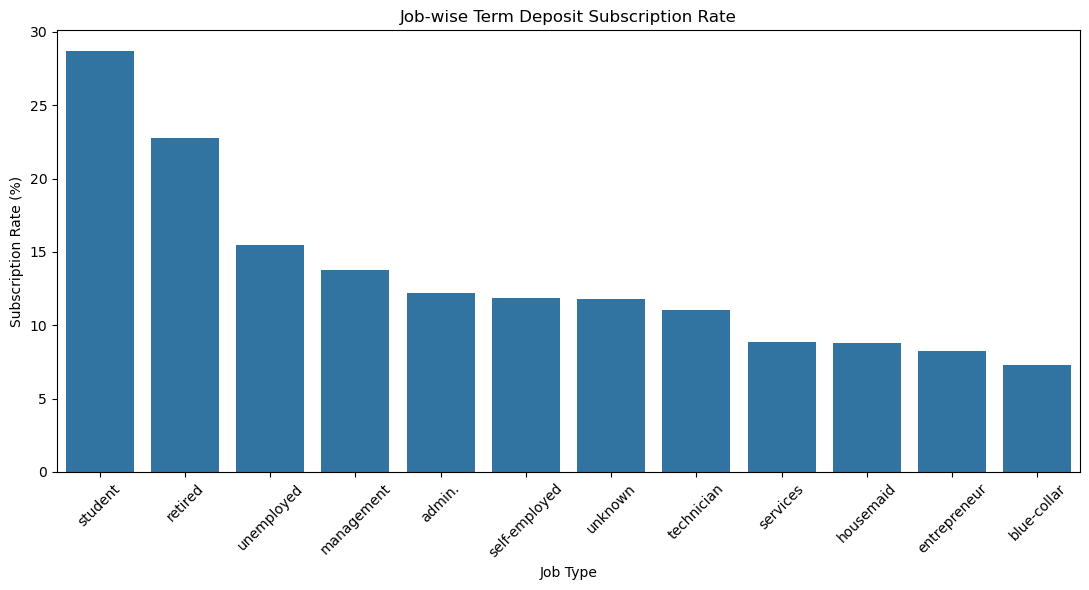

In [16]:

job_rate = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_rate = job_rate.sort_values(
    by='yes',
    ascending=False
)

print(job_rate.round(2))

# Visualization
plt.figure(figsize=(11, 6))

sns.barplot(
    x=job_rate.index,
    y=job_rate['yes']
)

plt.title('Job-wise Term Deposit Subscription Rate')
plt.xlabel('Job Type')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


y                 no    yes
job                        
student        71.32  28.68
retired        77.21  22.79
unemployed     84.50  15.50
management     86.24  13.76
admin.         87.80  12.20
self-employed  88.16  11.84
unknown        88.19  11.81
technician     88.94  11.06
services       91.12   8.88
housemaid      91.21   8.79
entrepreneur   91.73   8.27
blue-collar    92.73   7.27


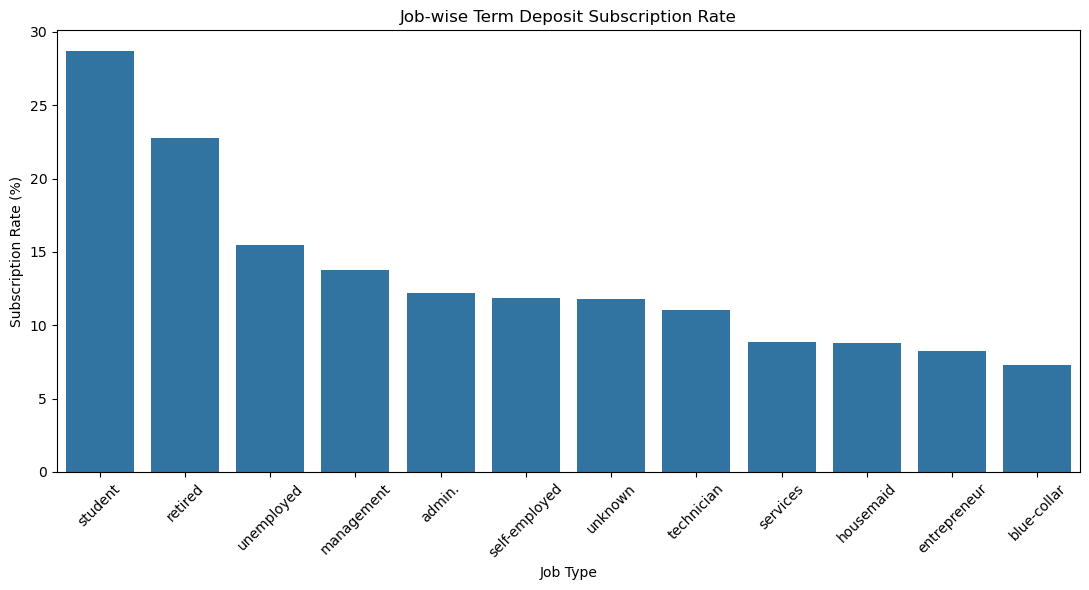

In [17]:

job_rate = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_rate = job_rate.sort_values(
    by='yes',
    ascending=False
)

print(job_rate.round(2))

# Visualization
plt.figure(figsize=(11, 6))

sns.barplot(
    x=job_rate.index,
    y=job_rate['yes']
)

plt.title('Job-wise Term Deposit Subscription Rate')
plt.xlabel('Job Type')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


**Job-wise Subscription Rate – Observation:**

Students and retired customers show the highest term deposit subscription rates among different job categories. Unemployed customers also show relatively good subscription rates. Blue-collar customers have the lowest subscription rate. The bank can consider focusing its marketing campaigns on customer segments with higher subscription rates.

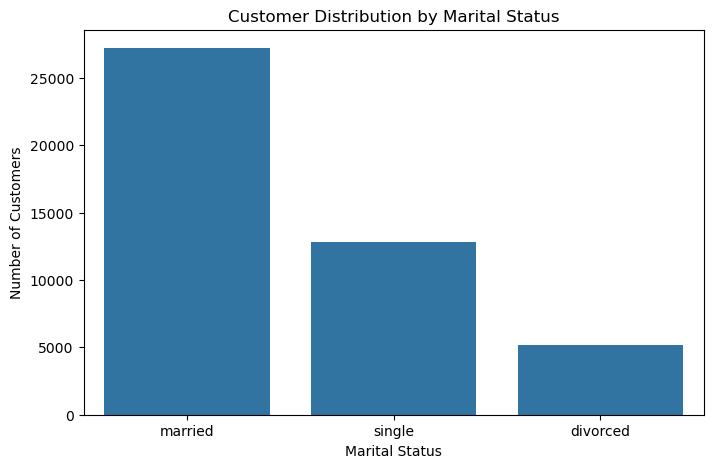

In [18]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='marital',
    order=df['marital'].value_counts().index
)

plt.title('Customer Distribution by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')

plt.show()


Marital Status – Observation:

Married customers represent the largest segment of the bank's customer base, followed by single and divorced customers. The bank should analyze subscription rates across these groups to identify potential customers.

y            no    yes
marital               
divorced  88.05  11.95
married   89.88  10.12
single    85.05  14.95


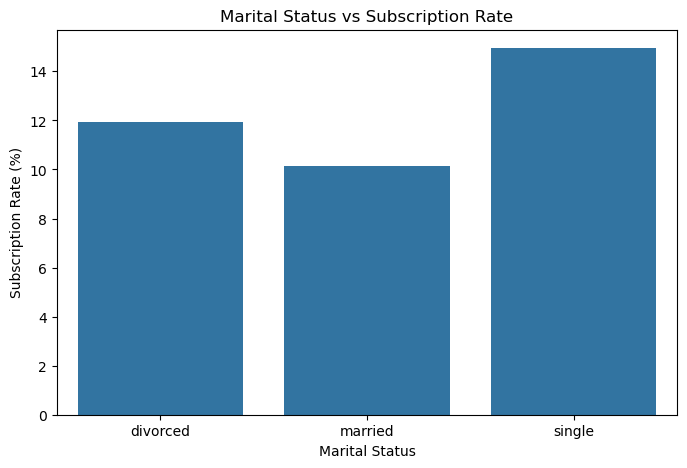

In [19]:

marital_rate = pd.crosstab(
    df['marital'],
    df['y'],
    normalize='index'
) * 100

print(marital_rate.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_rate.index,
    y=marital_rate['yes']
)

plt.title('Marital Status vs Subscription Rate')
plt.xlabel('Marital Status')
plt.ylabel('Subscription Rate (%)')

plt.show()


**Marital Status vs Subscription – Observation:**

Single customers have the highest term deposit subscription rate of 14.95%, followed by divorced customers at 11.95%. Married customers show the lowest subscription rate of 10.12%. The bank can consider focusing more on single customers while planning targeted marketing campaigns.

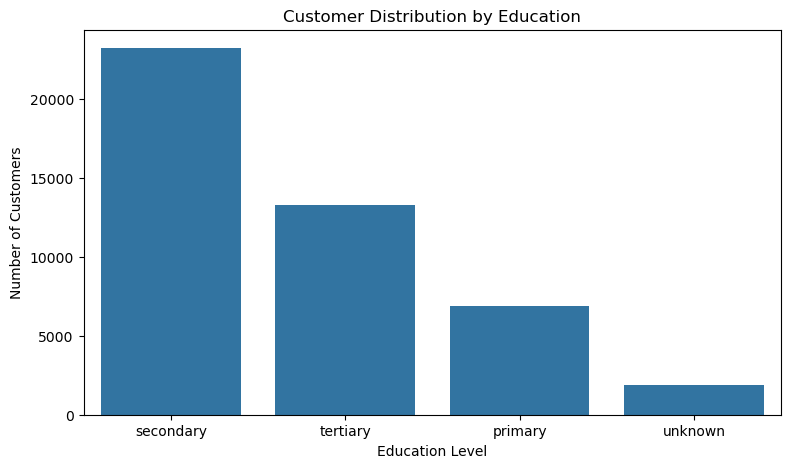

In [20]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='education',
    order=df['education'].value_counts().index
)

plt.title('Customer Distribution by Education')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.show()


**Education Distribution – Observation:**

Most customers have secondary education, followed by tertiary and primary education. Customers with unknown education information represent the smallest group. The bank can analyze education levels further to understand customer subscription behaviour.

In [21]:

# 1. Education-wise subscription rate
print("EDUCATION SUBSCRIPTION RATE")
print(pd.crosstab(df['education'], df['y'],
                  normalize='index').round(3) * 100)

# 2. Housing loan analysis
print("\nHOUSING LOAN")
print(pd.crosstab(df['housing'], df['y'],
                  normalize='index').round(3) * 100)

# 3. Personal loan analysis
print("\nPERSONAL LOAN")
print(pd.crosstab(df['loan'], df['y'],
                  normalize='index').round(3) * 100)

# 4. Contact type analysis
print("\nCONTACT TYPE")
print(pd.crosstab(df['contact'], df['y'],
                  normalize='index').round(3) * 100)

# 5. Numerical summary
print("\nNUMERICAL SUMMARY")
print(df[['age', 'balance', 'duration',
          'campaign', 'pdays', 'previous']].describe().round(2))


EDUCATION SUBSCRIPTION RATE
y            no   yes
education            
primary    91.4   8.6
secondary  89.4  10.6
tertiary   85.0  15.0
unknown    86.4  13.6

HOUSING LOAN
y          no   yes
housing            
no       83.3  16.7
yes      92.3   7.7

PERSONAL LOAN
y       no   yes
loan            
no    87.3  12.7
yes   93.3   6.7

CONTACT TYPE
y            no   yes
contact              
cellular   85.1  14.9
telephone  86.6  13.4
unknown    95.9   4.1

NUMERICAL SUMMARY
            age    balance  duration  campaign     pdays  previous
count  45211.00   45211.00  45211.00  45211.00  45211.00  45211.00
mean      40.94    1362.27    258.16      2.76     40.20      0.58
std       10.62    3044.77    257.53      3.10    100.13      2.30
min       18.00   -8019.00      0.00      1.00     -1.00      0.00
25%       33.00      72.00    103.00      1.00     -1.00      0.00
50%       39.00     448.00    180.00      2.00     -1.00      0.00
75%       48.00    1428.00    319.00      3.00     

In [22]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# Remove duration to avoid data leakage
X = df.drop(['y', 'duration'], axis=1)
y = df['y'].map({'no': 0, 'yes': 1})

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Preprocessing completed!")


Training Data: (36168, 15)
Testing Data: (9043, 15)
Preprocessing completed!


In [23]:

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced'
    ),
    'Decision Tree': DecisionTreeClassifier(
        random_state=42, class_weight='balanced'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42,
        class_weight='balanced_subsample', n_jobs=-1
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=100, random_state=42,
        class_weight='balanced', n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

    print(name, "completed")

comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by='F1 Score', ascending=False
)

print("\nMODEL COMPARISON")
display(comparison.round(4))


Logistic Regression completed
Decision Tree completed
Random Forest completed
Extra Trees completed

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722
3,Extra Trees,0.8844,0.5123,0.2561,0.3415,0.7611
2,Random Forest,0.8937,0.6374,0.2127,0.3189,0.7916
1,Decision Tree,0.8402,0.3059,0.2883,0.2968,0.6008


In [24]:
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722
3,Extra Trees,0.8844,0.5123,0.2561,0.3415,0.7611
2,Random Forest,0.8937,0.6374,0.2127,0.3189,0.7916
1,Decision Tree,0.8402,0.3059,0.2883,0.2968,0.6008


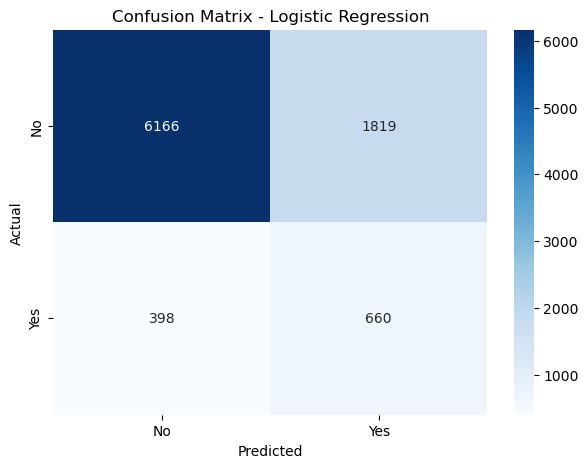

                precision    recall  f1-score   support

Not Subscribed       0.94      0.77      0.85      7985
    Subscribed       0.27      0.62      0.37      1058

      accuracy                           0.75      9043
     macro avg       0.60      0.70      0.61      9043
  weighted avg       0.86      0.75      0.79      9043



In [25]:

# Select best model
best_model_name = 'Logistic Regression'
best_model = trained_models[best_model_name]

# Predictions
y_pred = best_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification Report
print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Subscribed', 'Subscribed']
))


In [26]:

print("BEST MODEL:", best_model_name)

print("\nMODEL PERFORMANCE:")
print(comparison.iloc[0])

print("\nBUSINESS CONCLUSION:")
print("Logistic Regression achieved the highest Recall and F1-score.")
print("It is selected as the primary model for identifying")
print("potential term deposit subscribers.")


BEST MODEL: Logistic Regression

MODEL PERFORMANCE:
Model        Logistic Regression
Accuracy                0.754838
Precision               0.266236
Recall                  0.623819
F1 Score                0.373198
ROC AUC                 0.772238
Name: 0, dtype: object

BUSINESS CONCLUSION:
Logistic Regression achieved the highest Recall and F1-score.
It is selected as the primary model for identifying
potential term deposit subscribers.


### Business Recommendations

1. Focus on customer segments with higher subscription rates, especially students, retired and single customers.
2. Prefer cellular communication where possible.
3. Use customer loan and financial information to improve campaign targeting.
4. Avoid repeatedly contacting customers without considering previous campaign outcomes.
5. Use predictive models to prioritize customers who are more likely to subscribe.
6. Monitor model recall and precision to improve marketing effectiveness.

### Challenges Faced

1. **Class Imbalance:** Only 11.70% of customers subscribed to term deposits. Class weights were used to address imbalance.
2. **Categorical Variables:** One-Hot Encoding was applied to convert categorical features into numerical values.
3. **Feature Scaling:** StandardScaler was used for numerical features.
4. **Data Leakage:** Duration was excluded because it is not known before a marketing call.
5. **Model Selection:** Multiple classification algorithms were compared using accuracy, precision, recall, F1-score and ROC-AUC.

### Final Conclusion

The Logistic Regression model was selected as the best model based on its F1 Score of 37.32% and Recall of 62.38%.

The model achieved 75.48% accuracy and a ROC AUC score of 77.22%. It can identify approximately 62% of customers who subscribe to the bank's term deposit.

Although the model provides a reasonable baseline, its precision is 26.62%, indicating that many predicted positive customers do not actually subscribe.

This model can help the bank's marketing team identify potential customers and improve campaign targeting. Further improvements can be explored through hyperparameter tuning and handling class imbalance.

In [27]:
import shutil

shutil.make_archive(
    "Portuguese_Bank_Marketing_Prediction",
    "zip",
    root_dir="."
)

'C:\\Users\\HP\\Portuguese_Bank_Marketing_Prediction\\Portuguese_Bank_Marketing_Prediction.zip'

In [28]:
import os
print(os.path.abspath("Portuguese_Bank_Marketing_Prediction.zip"))

C:\Users\HP\Portuguese_Bank_Marketing_Prediction\Portuguese_Bank_Marketing_Prediction.zip
